# Diagnostics and robustness

This notebook recomputes all sensitivity samples with the unchanged production formula, evaluates design-matrix geometry, and summarizes influence and residual diagnostics. R-squared values across different samples are not model-selection scores.

In [1]:
from pathlib import Path
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent.resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from broadway_research.ingest import load

# Public clones must supply the authorized six-sheet workbook separately.
# Set BROADWAY_INPUT_DIR to the directory containing that workbook.
input_value = os.environ.get("BROADWAY_INPUT_DIR")
if not input_value:
    raise FileNotFoundError("Set BROADWAY_INPUT_DIR to the authorized workbook directory.")
input_dir = Path(input_value)
if not input_dir.exists() or not list(input_dir.glob("*.xlsx")):
    raise FileNotFoundError(
        "Authorized source workbook not found. Set BROADWAY_INPUT_DIR to its containing directory. "
        "The workbook is intentionally excluded from the public repository."
    )

production, market = load(input_dir)
print(f"Loaded authorized inputs: {production.shape[0]} production aggregates and {market.shape[0]} market weeks")

Loaded authorized inputs: 67 production aggregates and 501 market weeks


In [2]:
from broadway_research.production_analysis import fit, formula, samples
from broadway_research.diagnostics import inspect
from statsmodels.stats.diagnostic import het_breuschpagan

primary_formula = formula(production)
robustness = []
for label, sample in samples(production).items():
    fitted = fit(sample)
    interval = fitted.conf_int().loc["log_seats"]
    robustness.append({
        "sample": label, "N": int(fitted.nobs), "R_squared": fitted.rsquared,
        "adjusted_R_squared": fitted.rsquared_adj,
        "capacity_coefficient": fitted.params["log_seats"],
        "ci95_low": interval.iloc[0], "ci95_high": interval.iloc[1],
        "HC3_p_value": fitted.pvalues["log_seats"],
        "formula_unchanged": formula(sample) == primary_formula,
    })
robustness = pd.DataFrame(robustness)
assert robustness["formula_unchanged"].all()
robustness

,sample,N,R_squared,adjusted_R_squared,capacity_coefficient,ci95_low,ci95_high,HC3_p_value,formula_unchanged
0,Full sample,67,0.607957,0.425003,1.007385,0.529649,1.485121,0.000036,True
1,Without Hamilton,66,0.568097,0.376140,1.007385,0.529649,1.485121,0.000036,True
2,Without top 5%,63,0.531122,0.307847,0.923827,0.454106,1.393549,0.000116,True
3,At least 20 weeks,51,0.692047,0.469047,0.796268,0.296038,1.296498,0.001809,True


In [3]:
full_fit = fit(production)
diagnostics = inspect(full_fit)
influence = full_fit.get_influence()
leverage = influence.hat_matrix_diag
cooks = influence.cooks_distance[0]
diagnostics.update({
    "median_leverage": float(np.median(leverage)),
    "observations_above_2p_over_n": int((leverage > 2 * full_fit.model.exog.shape[1] / full_fit.nobs).sum()),
    "max_cooks_distance": float(np.max(cooks)),
    "observations_above_cooks_4_over_n": int((cooks > 4 / full_fit.nobs).sum()),
})
pd.Series(diagnostics)

rank                                  22.000000
columns                               22.000000
condition_number                     229.664868
max_leverage                           1.000000
median_leverage                        0.305623
observations_above_2p_over_n           1.000000
max_cooks_distance                   290.764584
observations_above_cooks_4_over_n      5.000000
dtype: float64

In [4]:
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(full_fit.resid, full_fit.model.exog)
pd.Series({"BP_LM": bp_lm, "BP_LM_p": bp_lm_p, "BP_F": bp_f, "BP_F_p": bp_f_p})

BP_LM      23.082039
BP_LM_p     0.339620
BP_F        1.126225
BP_F_p      0.358221
dtype: float64

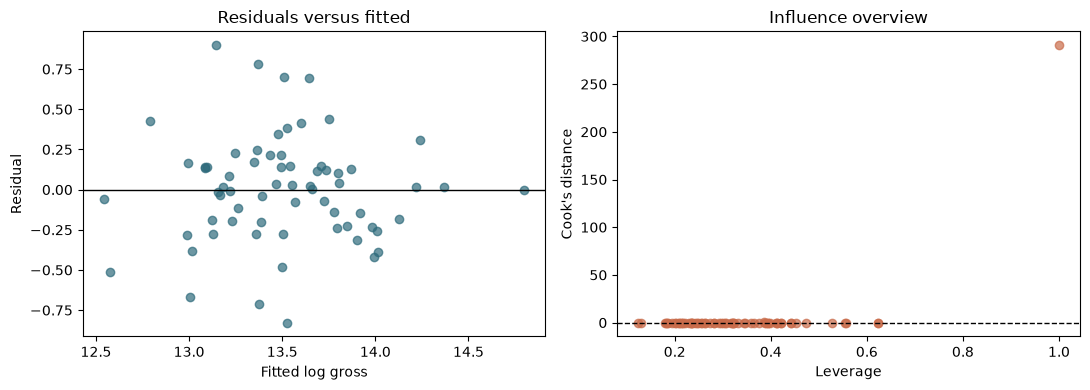

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(full_fit.fittedvalues, full_fit.resid, alpha=.7, color="#2f6b7c")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(xlabel="Fitted log gross", ylabel="Residual", title="Residuals versus fitted")
axes[1].scatter(leverage, cooks, alpha=.7, color="#c96c4b")
axes[1].axhline(4 / full_fit.nobs, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Leverage", ylabel="Cook's distance", title="Influence overview")
fig.tight_layout();

In [6]:
production["Music_Style"].value_counts().to_frame("productions")

,productions
Music_Style,
Traditional,27
Pop/Rock,24
Mixed/Other,6
Folk/Country,5
Jazz/Swing,4
HipHop,1


Hamilton is the sole HipHop observation, so excluding it removes both an influential production and an entire style level. The check therefore changes category support as well as the sample. HC3 protects inference against heteroskedasticity under the maintained linear model, but it cannot repair sparse cells, omitted variables, or extreme leverage.